In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [13]:
import os
import re
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

BASE_PATHS = {
    "NMF": Path("/home/moshtasa/Research/phd-svd-recsys/Book/0323_similar_pr_details/NMF-0323/result/NMF_run/NMF_bar_figures"),
    "SVD": Path("/home/moshtasa/Research/phd-svd-recsys/Book/0323_similar_pr_details/SVD-0323/result/SVD-run/SVD_bar_figures"),
}

def parse_txt(file_path):
    data = {}
    current_k = None

    with open(file_path, "r") as f:
        for line in f:
            line = line.strip()

            if line.startswith("k ="):
                current_k = int(line.split("=")[1].strip())
                data[current_k] = {}

            elif ":" in line and current_k is not None:
                match = re.match(r"(.*?)\:\s*([0-9.]+)", line)
                if match:
                    label = match.group(1).strip()
                    value = float(match.group(2))
                    data[current_k][label] = value

    return data

def generate_colors(n_list):
    cmap = plt.cm.get_cmap('tab20', len(n_list))
    return {n: cmap(i) for i, n in enumerate(n_list)}

def extract_genre(folder_name):
    parts = folder_name.lower().split("_")
    return parts[1] if len(parts) > 1 else None

nmf_map = {
    extract_genre(f): f
    for f in os.listdir(BASE_PATHS["NMF"])
    if (BASE_PATHS["NMF"] / f).is_dir()
}

svd_map = {
    extract_genre(f): f
    for f in os.listdir(BASE_PATHS["SVD"])
    if (BASE_PATHS["SVD"] / f).is_dir()
}

common_genres = sorted(set(nmf_map.keys()) & set(svd_map.keys()))
print("Detected genres:", common_genres)

# =========================
# MAIN LOOP
# =========================

for genre_key in common_genres:

    genre = genre_key.capitalize()

    nmf_folder = nmf_map[genre_key]
    svd_folder = svd_map[genre_key]

    paths = {
        "NMF": BASE_PATHS["NMF"] / nmf_folder,
        "SVD": BASE_PATHS["SVD"] / svd_folder,
    }

    parsed_data = {}

    for method, folder_path in paths.items():
        txt_files = [f for f in os.listdir(folder_path) if f.endswith(".txt")]
        if not txt_files:
            print(f"No txt in {folder_path}")
            continue

        txt_path = folder_path / txt_files[0]
        parsed_data[method] = parse_txt(txt_path)

    if len(parsed_data) < 2:
        print(f"Skipping {genre_key}")
        continue

    ks = [k for k in sorted(parsed_data["NMF"].keys()) if k in [15, 25, 35]]
    if not ks:
        continue

    n_types = sorted(set(
        n
        for method in parsed_data
        for k in ks
        for n in parsed_data[method][k].keys()
    ), key=lambda x: (x != "original", int(x.replace("u", "")) if x != "original" else -1))

    color_map = generate_colors(n_types)

    fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharey=True)

    legend_handles = []
    legend_labels = []

    for ax, method in zip(axes, ["NMF", "SVD"]):

        data = parsed_data[method]

        x = np.arange(len(ks)) * 1.3
        width = 1.1 / len(n_types)

        for i, n in enumerate(n_types):
            vals = [data[k].get(n, 0) for k in ks]

            bars = ax.bar(
                x + (i - len(n_types)/2) * width + width/2,
                vals,
                width=width,
                color=color_map[n],
                edgecolor="black",
                linewidth=1.5,
                label=n
            )

            # collect legend only once
            if method == "NMF":
                legend_handles.append(bars[0])
                legend_labels.append(n)

        ax.spines["top"].set_visible(True)
        ax.spines["right"].set_visible(True)
        ax.yaxis.grid(True, linestyle="--", linewidth=0.6, alpha=0.6)

        ax.set_title(f"{method} - {genre}", fontsize=28, fontweight="bold", pad=10)

        ax.set_xticks(x)
        ax.set_xticklabels(ks, fontsize=24)
        ax.tick_params(axis='y', labelsize=24)

        ax.set_ylim(0, 40)
        ax.set_xlabel("k (recommendation size)", fontsize=26, fontweight="bold", labelpad=10)

    axes[0].set_ylabel("Avg count per user", fontsize=26, fontweight="bold", labelpad=10)

    # =========================
    # COMPACT LEGEND (FIXED)
    # =========================
    fig.legend(
        legend_handles,
        legend_labels,
        loc="upper center",
        bbox_to_anchor=(0.35, 1.1),   # ✅ no wasted top space
        fontsize=26,
        ncol=min(len(legend_labels), 8),
        handlelength=1.3,
        handletextpad=0.4,
        columnspacing=0.7
    )

    # tighter layout to remove empty space
    plt.tight_layout(rect=[0, 0, 1, 0.93])

    filename = f"comparision - {genre}.png"

    plt.savefig(paths["NMF"] / filename, dpi=300, bbox_inches="tight")
    plt.savefig(paths["SVD"] / filename, dpi=300, bbox_inches="tight")
    plt.close()

    print(f"Saved: {filename}")

print("DONE ✅")

Detected genres: ['adult', 'adventure', "children's", 'classics', 'drama', 'fantasy', 'historical', 'horror', 'mystery', 'nonfiction', 'romance', 'science', 'thriller']


/tmp/ipykernel_1267871/64704318.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(n_list))


Saved: comparision - Adult.png


/tmp/ipykernel_1267871/64704318.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(n_list))


Saved: comparision - Adventure.png


...

Saved: comparision - Romance.png


/tmp/ipykernel_1267871/64704318.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(n_list))


Saved: comparision - Science.png


/tmp/ipykernel_1267871/64704318.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(n_list))


Saved: comparision - Thriller.png
DONE ✅


In [94]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict

# ── Paths ──
BASE_NMF = "/home/moshtasa/Research/phd-svd-recsys/Book/0323_similar_pr_details/NMF-0323/result/NMF_run"
BASE_SVD = "/home/moshtasa/Research/phd-svd-recsys/Book/0323_similar_pr_details/SVD-0323/result/SVD-run"

NMF_FIG_DIR = os.path.join(BASE_NMF, "NMF_details_figures")
SVD_FIG_DIR = os.path.join(BASE_SVD, "SVD_details_figures")

os.makedirs(NMF_FIG_DIR, exist_ok=True)
os.makedirs(SVD_FIG_DIR, exist_ok=True)

# =========================
# LOAD DATA
# =========================

def load_data(BASE):
    BI_DIR = os.path.join(BASE, "bi")
    MU_DIR = os.path.join(BASE, "mio")

    BI_PATTERN = re.compile(r"^f_(.+?)_(\d+)u_pos5_neg1_books_bi_per_genre\.csv$")

    merged_data = {}

    for fname in os.listdir(BI_DIR):
        m = BI_PATTERN.match(fname)
        if not m:
            continue

        genre_key = m.group(1)
        n = int(m.group(2))

        bi_path = os.path.join(BI_DIR, fname)
        mu_path = os.path.join(MU_DIR, fname.replace("_bi_", "_mu_"))

        if not os.path.exists(mu_path):
            continue

        df_bi = pd.read_csv(bi_path)
        df_mu = pd.read_csv(mu_path)

        merge_cols = ["genre"]
        if "is_target" in df_bi.columns and "is_target" in df_mu.columns:
            merge_cols.append("is_target")

        df_merged = pd.merge(df_mu, df_bi, on=merge_cols, how="outer")
        merged_data[(genre_key, n)] = df_merged

    genre_groups = defaultdict(dict)
    for (genre_key, n), df in merged_data.items():
        genre_groups[genre_key][n] = df

    return genre_groups

nmf_groups = load_data(BASE_NMF)
svd_groups = load_data(BASE_SVD)

# =========================
# STYLE
# =========================

plt.style.use("seaborn-v0_8-pastel")

TARGET_COLOR = "#5B3A29"
TARGET_LINEWIDTH = 3.5
NON_TARGET_LINEWIDTH = 1.5

PASTEL_COLORS = [
    "#AEC6CF","#FFD1DC","#B5EAD7","#FFDAC1","#C3B1E1","#F3E5AB",
    "#FFB7B2","#B0E0E6","#D5AAFF","#FFFACD","#E0BBE4","#957DAD",
    "#D4E157","#80CBC4","#F48FB1",
]

# =========================
# MAIN LOOP
# =========================

for genre_key in sorted(nmf_groups.keys()):

    if genre_key not in svd_groups:
        continue

    nmf_dict = nmf_groups[genre_key]
    svd_dict = svd_groups[genre_key]

    sorted_ns = sorted(set(nmf_dict.keys()) & set(svd_dict.keys()))
    if not sorted_ns:
        continue

    sample_df = nmf_dict[sorted_ns[0]]
    target_rows = sample_df[sample_df["is_target"] == "target"]
    if target_rows.empty:
        continue

    target_genre_name = target_rows["genre"].iloc[0]

    def build_series(n_dict):
        all_genres = set()
        for n in sorted_ns:
            all_genres.update(n_dict[n]["genre"].tolist())
        all_genres = sorted(all_genres)

        series = {}
        for g in all_genres:
            pts = []
            for n in sorted_ns:
                df = n_dict[n]
                row = df[df["genre"] == g]
                if not row.empty:
                    val = row["avg_bi"].values[0] + row["global_mean_mu"].values[0]
                    pts.append((n, val))
            series[g] = pts

        return series, all_genres

    nmf_series, all_genres = build_series(nmf_dict)
    svd_series, _ = build_series(svd_dict)

    non_target_genres = [g for g in all_genres if g != target_genre_name]

    color_map = {}
    for i, g in enumerate(non_target_genres):
        color_map[g] = PASTEL_COLORS[i % len(PASTEL_COLORS)]
    color_map[target_genre_name] = TARGET_COLOR

    positions = list(range(len(sorted_ns)))
    n_to_pos = {n: p for n, p in zip(sorted_ns, positions)}

    # =========================
    # FIGURE (FIXED SIZE + LAYOUT)
    # =========================

    fig, axes = plt.subplots(
        1, 2,
        figsize=(16, 6),   # ✅ tighter width
        sharey=True,
        constrained_layout=True  # ✅ auto spacing
    )

    legend_handles = {}

    for ax, series, model_name in zip(
        axes,
        [nmf_series, svd_series],
        ["NMF", "SVD"]
    ):

        for g in non_target_genres:
            pts = series.get(g, [])
            if pts:
                xs = [n_to_pos[x] for x, _ in pts]
                ys = [y for _, y in pts]
                line, = ax.plot(xs, ys, marker="o",
                                color=color_map[g],
                                linewidth=NON_TARGET_LINEWIDTH,
                                markersize=9,
                                alpha=0.8,
                                label=g)
                if g not in legend_handles:
                    legend_handles[g] = line

        pts = series.get(target_genre_name, [])
        if pts:
            xs = [n_to_pos[x] for x, _ in pts]
            ys = [y for _, y in pts]
            line, = ax.plot(xs, ys, marker="o",
                            color=TARGET_COLOR,
                            linewidth=TARGET_LINEWIDTH,
                            markersize=7,
                            label=f"{target_genre_name} (target)",
                            zorder=10)
            legend_handles[target_genre_name] = line

        pretty = genre_key.replace("_", " ")

        ax.tick_params(axis='y', labelsize=18)
        ax.tick_params(axis='x', labelsize=20)

        ax.set_title(f"{model_name} - {pretty}", fontsize=26, fontweight='bold')
        ax.set_xlabel("Number of Fictitious Users (n)", fontsize=22, fontweight="bold")

        ax.set_xticks(positions)
        ax.set_xticklabels([str(n) for n in sorted_ns], rotation=45)

        ax.grid(True, alpha=0.3)

    axes[0].set_ylabel(r"$\mu$ + $b_i$", fontweight="bold", fontsize=26)

    # =========================
    # LEGEND (HORIZONTAL TOP)
    # =========================

    fig.legend(
    list(legend_handles.values()),
    list(legend_handles.keys()),
    loc="upper center",
    bbox_to_anchor=(0.5, 1.22),   # 🔥 pull legend closer
    fontsize=20,                  # 🔥 smaller text
    ncol=min(len(legend_handles), 7),  # 🔥 wrap instead of stretching
    handlelength=1.2,             # 🔥 shorter line samples
    handletextpad=0.6,            # 🔥 tighter spacing text
    columnspacing=0.8             # 🔥 tighter columns
)

    # =========================
    # SAVE
    # =========================

    nmf_path = os.path.join(NMF_FIG_DIR, f"{genre_key}_comparison.png")
    svd_path = os.path.join(SVD_FIG_DIR, f"{genre_key}_comparison.png")

    fig.savefig(nmf_path, dpi=150, bbox_inches="tight")
    fig.savefig(svd_path, dpi=150, bbox_inches="tight")

    plt.close(fig)

    print(f"Saved: {nmf_path}")
    print(f"Saved: {svd_path}")

print("Done!")

Saved: /home/moshtasa/Research/phd-svd-recsys/Book/0323_similar_pr_details/NMF-0323/result/NMF_run/NMF_details_figures/Adult_comparison.png
Saved: /home/moshtasa/Research/phd-svd-recsys/Book/0323_similar_pr_details/SVD-0323/result/SVD-run/SVD_details_figures/Adult_comparison.png
Saved: /home/moshtasa/Research/phd-svd-recsys/Book/0323_similar_pr_details/NMF-0323/result/NMF_run/NMF_details_figures/Adventure_comparison.png
Saved: /home/moshtasa/Research/phd-svd-recsys/Book/0323_similar_pr_details/SVD-0323/result/SVD-run/SVD_details_figures/Adventure_comparison.png
Saved: /home/moshtasa/Research/phd-svd-recsys/Book/0323_similar_pr_details/NMF-0323/result/NMF_run/NMF_details_figures/Children_s_comparison.png
Saved: /home/moshtasa/Research/phd-svd-recsys/Book/0323_similar_pr_details/SVD-0323/result/SVD-run/SVD_details_figures/Children_s_comparison.png
Saved: /home/moshtasa/Research/phd-svd-recsys/Book/0323_similar_pr_details/NMF-0323/result/NMF_run/NMF_details_figures/Classics_comparison.png

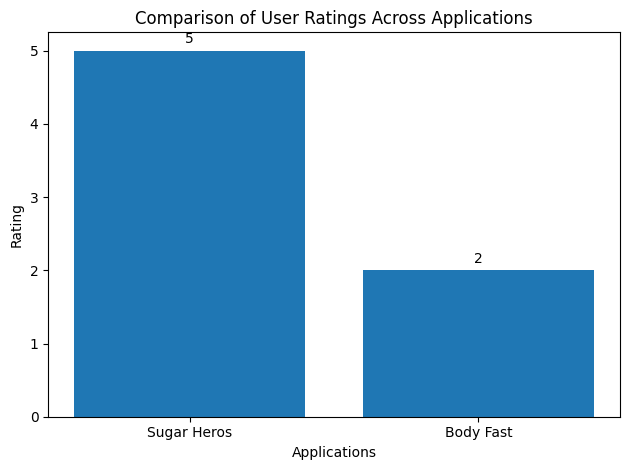

In [ ]:
import matplotlib.pyplot as plt

# Data from your LaTeX table
columns = ["User ID", "App Name", "Rating", "Category"]
data = [
    ["1", "Sugar Heros", "5", "Games"],
    ["2", "Body Fast", "2", "Medical"]
]

# Create figure
fig, ax = plt.subplots()
ax.axis('off')

# Create table
table = ax.table(
    cellText=data,
    colLabels=columns,
    loc='center',
    cellLoc='center'
)

# Improve styling
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.5)

# Bold header row
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight='bold')

# Save figure
plt.savefig("/home/moshtasa/Research/phd-svd-recsys/Book/0323_similar_pr_details/Data/domain_analysis/figures/app_table_figure.png", bbox_inches='tight', dpi=300)

# Show figure
plt.show()